In [1]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# Set plot style
sns.set_theme(style="whitegrid")

In [3]:
# ==========================================
# STEP 1: LOAD & PREPROCESS DATASET
# ==========================================
file_path = 'UCI_Online_Sale_Sampled_15k (1).csv'
data = pd.read_csv(file_path)

# Convert InvoiceDate & calculate Total Revenue per item line
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
data['TotalAmount'] = data['Quantity'] * data['UnitPrice']

print("==========================================")
print("STEP 1: DATASET LOADED & PREPROCESSED")
print("==========================================")
print(f"Total Transaction Records: {data.shape[0]}")
print(f"Unique Customers Count:    {data['CustomerID'].nunique()}")
print("\nSample Cleaned Data (First 3 Rows):")
print(data[['InvoiceNo', 'CustomerID', 'Quantity', 'UnitPrice', 'TotalAmount', 'InvoiceDate']].head(3))

STEP 1: DATASET LOADED & PREPROCESSED
Total Transaction Records: 18270
Unique Customers Count:    200

Sample Cleaned Data (First 3 Rows):
   InvoiceNo  CustomerID  Quantity  UnitPrice  TotalAmount         InvoiceDate
0     536393     13747.0         8       9.95         79.6 2010-12-01 10:37:00
1     536559     17873.0        10       3.95         39.5 2010-12-01 14:54:00
2     536559     17873.0        24       0.85         20.4 2010-12-01 14:54:00


In [4]:
# ==========================================
# STEP 2: EXTRACT RFM FEATURES
# ==========================================
snapshot_date = data['InvoiceDate'].max() + dt.timedelta(days=1)

rfm = data.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
}).rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
}).reset_index()

print("\n==========================================")
print("STEP 2: RFM FEATURE EXTRACTION COMPLETE")
print("==========================================")
print(rfm.head())


STEP 2: RFM FEATURE EXTRACTION COMPLETE
   CustomerID  Recency  Frequency  Monetary
0     12360.0       52          3   2662.06
1     12383.0      185          5   1850.56
2     12449.0       22          4   4067.29
3     12490.0        5         10   5417.93
4     12512.0       66          2    138.03


In [5]:
# ==========================================
# STEP 3: FEATURE SCALING & NORMALIZATION
# ==========================================
rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print("\n==========================================")
print("STEP 3: FEATURE SCALING & STANDARDIZATION COMPLETE")
print("==========================================")
print("Scaled Matrix Shape:", rfm_scaled.shape)
print("Sample Scaled Feature Array (First Row):", rfm_scaled[0].round(4))




STEP 3: FEATURE SCALING & STANDARDIZATION COMPLETE
Scaled Matrix Shape: (200, 3)
Sample Scaled Feature Array (First Row): [0.0999 0.0038 1.0213]



STEP 4: CLUSTER EVALUATION METRICS
 K_Clusters       WCSS  Silhouette_Score
          2 293.384330          0.429043
          3 212.444080          0.350812
          4 166.533699          0.357505
          5 138.747915          0.337782
          6 119.592486          0.325603
          7 105.417201          0.312787


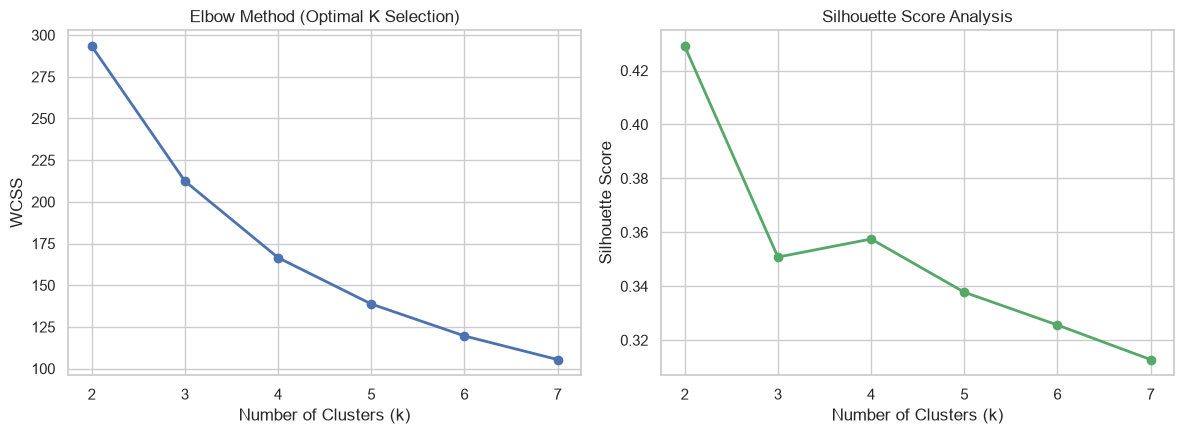

In [6]:
# ==========================================
# STEP 4: ELBOW METHOD & SILHOUETTE ANALYSIS
# ==========================================
wcss = []
silhouette_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, kmeans.labels_))

print("\n==========================================")
print("STEP 4: CLUSTER EVALUATION METRICS")
print("==========================================")
eval_df = pd.DataFrame({'K_Clusters': list(K_range), 'WCSS': wcss, 'Silhouette_Score': silhouette_scores})
print(eval_df.to_string(index=False))

# Visualization 1: Elbow Curve & Silhouette Scores
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(K_range, wcss, marker='o', color='b', linewidth=2)
plt.title('Elbow Method (Optimal K Selection)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')

plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='o', color='g', linewidth=2)
plt.title('Silhouette Score Analysis')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()



In [7]:
# ==========================================
# STEP 5: MODEL TRAINING (K-MEANS & DBSCAN)
# ==========================================
# K-Means Execution
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm['KMeans_Cluster'] = kmeans.fit_predict(rfm_scaled)

# DBSCAN Execution
dbscan = DBSCAN(eps=0.5, min_samples=4)
rfm['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)

# Persona Mapping
cluster_labels = {
    0: 'Champions',
    1: 'At-Risk Customers',
    2: 'Loyal Buyers',
    3: 'New / Recent Buyers'
}
rfm['Segment'] = rfm['KMeans_Cluster'].map(cluster_labels)

print("\n==========================================")
print("STEP 5: CLUSTER ASSIGNMENT & SUMMARY")
print("==========================================")
summary = rfm.groupby('Segment')[['Recency', 'Frequency', 'Monetary']].mean().round(2)
print("K-Means Segment Performance Summary:")
print(summary)

print("\nDBSCAN Cluster Distribution (-1 represents Noise/Outliers):")
print(rfm['DBSCAN_Cluster'].value_counts().rename(index={-1: 'Outliers/Noise'}))





STEP 5: CLUSTER ASSIGNMENT & SUMMARY
K-Means Segment Performance Summary:
                     Recency  Frequency  Monetary
Segment                                          
At-Risk Customers     181.42       1.29    342.34
Champions              14.15      11.85   4607.34
Loyal Buyers           77.54       4.14   1624.77
New / Recent Buyers    15.79       2.26    540.41

DBSCAN Cluster Distribution (-1 represents Noise/Outliers):
DBSCAN_Cluster
0                 98
1                 58
Outliers/Noise    41
2                  3
Name: count, dtype: int64


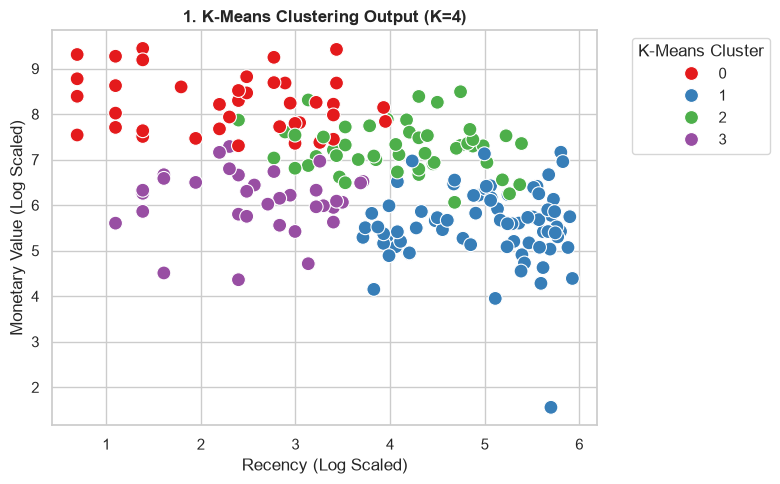

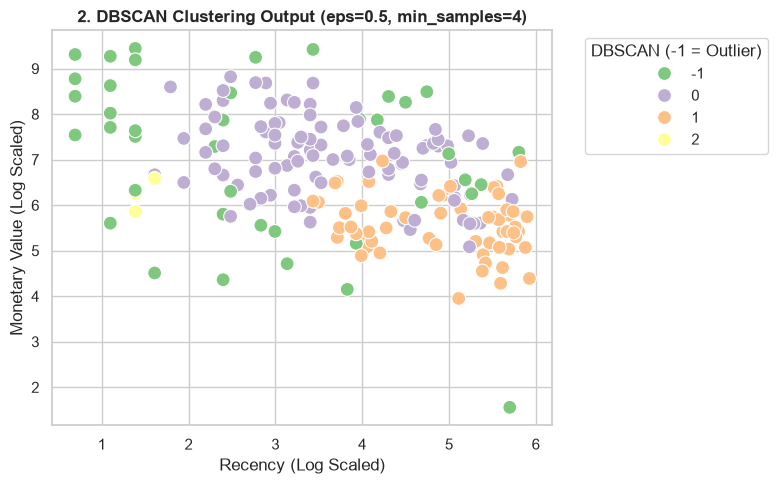

C:\Users\rishi\AppData\Local\Temp\ipykernel_8456\2650684361.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, x='Segment', palette='Set2', ax=axes[0])
C:\Users\rishi\AppData\Local\Temp\ipykernel_8456\2650684361.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_spend, x='Segment', y='Monetary', palette='Set2', ax=axes[1])


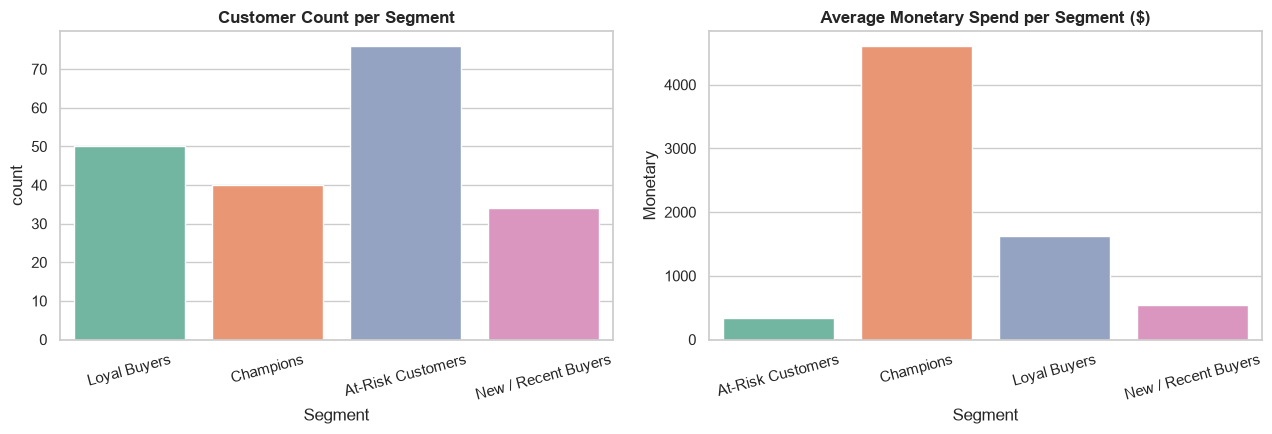

In [8]:
# ==========================================
# STEP 6: SEPARATE CLUSTERING VISUALIZATIONS
# ==========================================

# 1. K-Means Scatter Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=rfm_log['Recency'], 
    y=rfm_log['Monetary'], 
    hue=rfm['KMeans_Cluster'], 
    palette='Set1',
    s=100
)
plt.title('1. K-Means Clustering Output (K=4)', fontweight='bold')
plt.xlabel('Recency (Log Scaled)')
plt.ylabel('Monetary Value (Log Scaled)')
plt.legend(title='K-Means Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 2. DBSCAN Scatter Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=rfm_log['Recency'], 
    y=rfm_log['Monetary'], 
    hue=rfm['DBSCAN_Cluster'], 
    palette='Accent',
    s=100
)
plt.title('2. DBSCAN Clustering Output (eps=0.5, min_samples=4)', fontweight='bold')
plt.xlabel('Recency (Log Scaled)')
plt.ylabel('Monetary Value (Log Scaled)')
plt.legend(title='DBSCAN (-1 = Outlier)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 3. Final Persona Segment Analysis
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=rfm, x='Segment', palette='Set2', ax=axes[0])
axes[0].set_title('Customer Count per Segment', fontweight='bold')
axes[0].tick_params(axis='x', rotation=15)

avg_spend = rfm.groupby('Segment')['Monetary'].mean().reset_index()
sns.barplot(data=avg_spend, x='Segment', y='Monetary', palette='Set2', ax=axes[1])
axes[1].set_title('Average Monetary Spend per Segment ($)', fontweight='bold')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()



STEP 7: COMPARATIVE VISUALIZATION DISPLAY


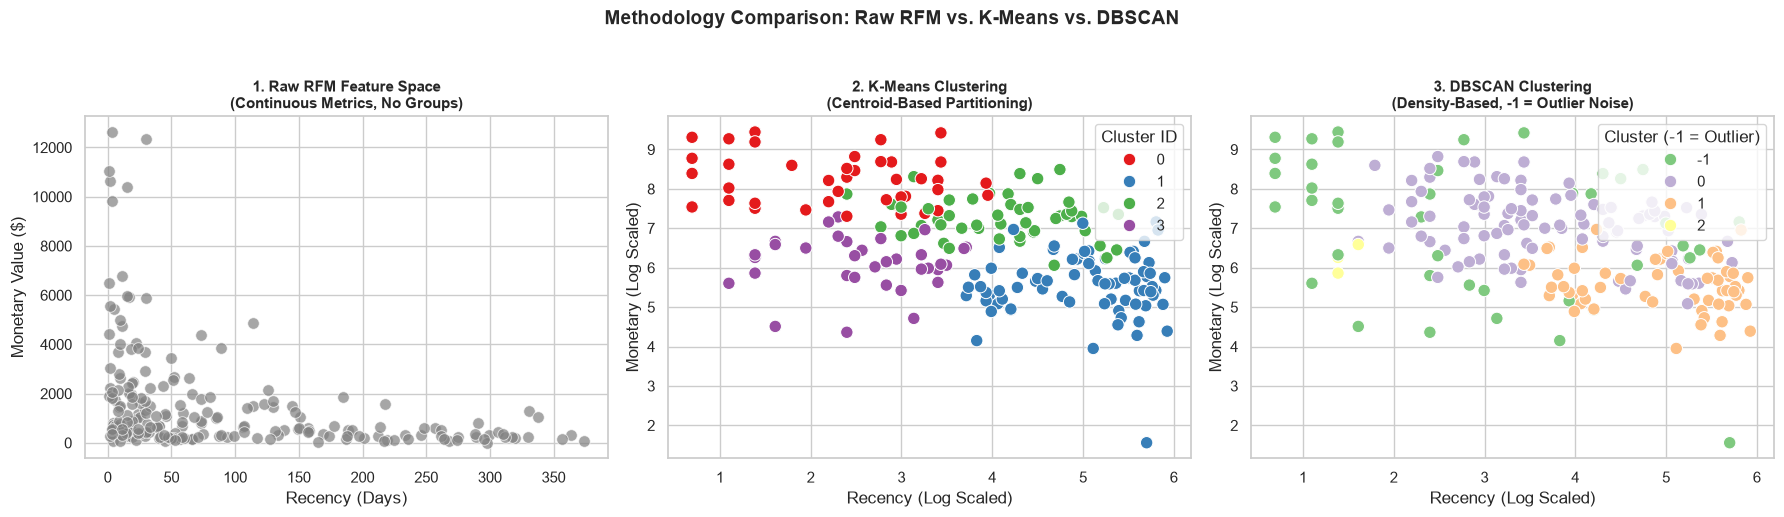

In [9]:
# ==========================================
# STEP 7: SIDE-BY-SIDE METHODOLOGY COMPARISON
# ==========================================
print("\n==========================================")
print("STEP 7: COMPARATIVE VISUALIZATION DISPLAY")
print("==========================================")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Raw RFM
sns.scatterplot(data=rfm, x='Recency', y='Monetary', color='gray', alpha=0.7, s=70, ax=axes[0])
axes[0].set_title('1. Raw RFM Feature Space\n(Continuous Metrics, No Groups)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Recency (Days)')
axes[0].set_ylabel('Monetary Value ($)')

# Subplot 2: K-Means
sns.scatterplot(x=rfm_log['Recency'], y=rfm_log['Monetary'], hue=rfm['KMeans_Cluster'], palette='Set1', s=80, ax=axes[1])
axes[1].set_title('2. K-Means Clustering\n(Centroid-Based Partitioning)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Recency (Log Scaled)')
axes[1].set_ylabel('Monetary (Log Scaled)')
axes[1].legend(title='Cluster ID', loc='upper right')

# Subplot 3: DBSCAN
sns.scatterplot(x=rfm_log['Recency'], y=rfm_log['Monetary'], hue=rfm['DBSCAN_Cluster'], palette='Accent', s=80, ax=axes[2])
axes[2].set_title('3. DBSCAN Clustering\n(Density-Based, -1 = Outlier Noise)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Recency (Log Scaled)')
axes[2].set_ylabel('Monetary (Log Scaled)')
axes[2].legend(title='Cluster (-1 = Outlier)', loc='upper right')

plt.suptitle('Methodology Comparison: Raw RFM vs. K-Means vs. DBSCAN', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()